In [37]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score

In [23]:
df = pd.read_csv("files/heart.csv")

In [24]:
df.shape
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [31]:
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [34]:
df.duplicated().sum()

np.int64(1)

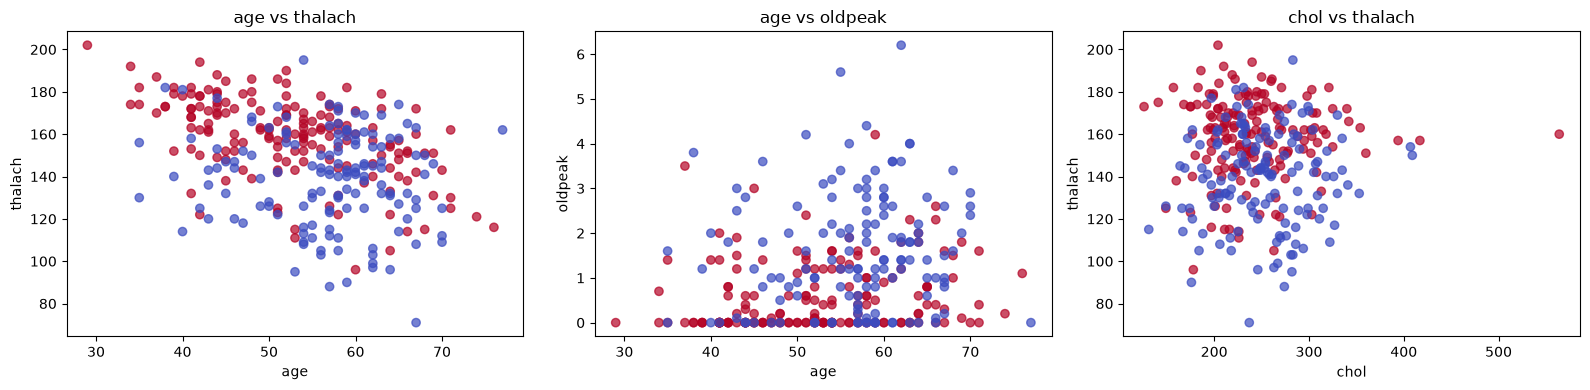

In [30]:

import matplotlib.pyplot as plt

features = [
    ("age", "thalach"),
    ("age", "oldpeak"),
    ("chol", "thalach")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (x, y) in zip(axes, features):
    ax.scatter(
        df[x],
        df[y],
        c=df["target"],
        cmap="coolwarm",
        alpha=0.7
    )
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{x} vs {y}")

plt.tight_layout()
plt.show()


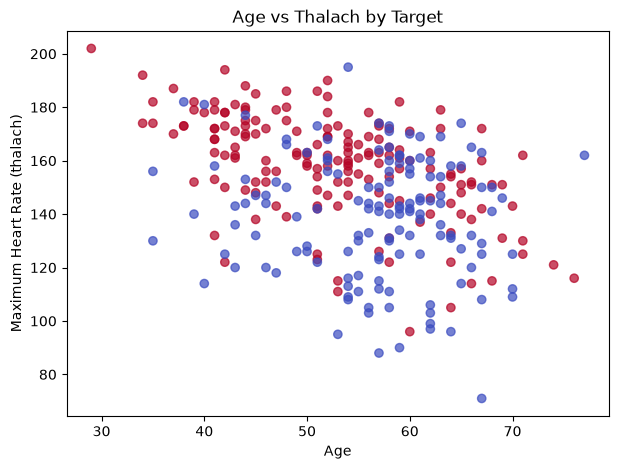

In [35]:
plot_df = df[["age", "thalach", "target"]]

plt.figure(figsize=(7, 5))
plt.scatter(
    plot_df["age"],
    plot_df["thalach"],
    c=plot_df["target"],
    cmap="coolwarm",
    alpha=0.7
)

plt.xlabel("Age")
plt.ylabel("Maximum Heart Rate (thalach)")
plt.title("Age vs Thalach by Target")
plt.show()

In [51]:
X = df[["age", "thalach"]]
y = df["target"]

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [53]:
model = make_pipeline(
    StandardScaler(),
    Perceptron(random_state=42)
)

In [54]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('perceptron', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['age','thalach']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [55]:
model.named_steps["perceptron"].coef_

array([[-0.14114318,  1.31658695]])

In [56]:
model.named_steps["perceptron"].intercept_

array([1.])

c:\Users\RoOnEy\Desktop\100 Days of Deep Learning\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


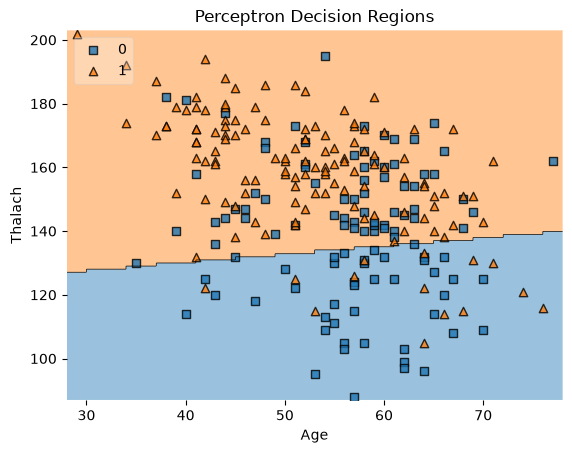

In [57]:
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_decision_regions

model.fit(X_train, y_train)

plot_decision_regions(
    X_train.to_numpy(),
    y_train.to_numpy(),
    clf=model,
    legend=2
)

plt.xlabel("Age")
plt.ylabel("Thalach")
plt.title("Perceptron Decision Regions")
plt.show()

In [58]:
y_pred = model.predict(X_test)

In [59]:
print(accuracy_score(y_pred,y_test))

0.6885245901639344
